<a href="https://colab.research.google.com/github/Lyra0710/Multimodal-Deep-Learning-for-Reliable-GRACE-Water-Storage-Trends/blob/main/notebooks/P_T_TWS_Drivers_and_Baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook looks at how precipitation (GPM IMERG) and 2 m air temperature (MERRA-2) drive GRACE terrestrial water storage (TWS). It also sets the baseline scores that the LSTM, TCN and Transformer models must beat.


In [ ]:
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "earthaccess", "pymannkendall", "h5netcdf", "netCDF4", "cartopy", "python-dotenv",
        "podaac-data-subscriber",
    ])
else:
    print("Not running in Google Colab; dependency installation skipped.")

Not running in Google Colab; dependency installation skipped.


In [3]:
from pathlib import Path
import json
import warnings
import sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "scripts" / "p_t_tws_data.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find the repository root. Run the notebook from a clone of the repository."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import p_t_tws_analysis as analysis
import p_t_tws_baselines as baselines
import p_t_tws_data as alignment

# grace_fo_persistence selects the Agg backend on import; restore inline plots.
%matplotlib inline
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Configuration


In [4]:
CONFIG_PATH = PROJECT_ROOT / "configs" / "p_t_tws_config.yaml"
ENV_FILE = PROJECT_ROOT / ".env"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
ALIGNED_FILE = PROCESSED_DIR / "p_t_tws_aligned_0.5deg.nc"

config = alignment.load_config(CONFIG_PATH, project_root=PROJECT_ROOT)
for directory in (PROCESSED_DIR, METRICS_DIR, FIGURES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

display(pd.DataFrame(config["splits"]).T)
print("Setup:", config["baselines"]["setup"], "| grid:", config["data"]["resolution_deg"], "deg")

,start,end
train,2019-01-01,2022-12-31
validation,2023-01-01,2023-12-31
test,2024-01-01,2025-12-31


Setup: nowcast | grid: 0.5 deg


## 2. Data access (NASA Earthdata)
* **GRACE/GRACE-FO** mascon CRI file `grace_fo_processing.py` keeps in `data/raw/`.
* **IMERG** and **MERRA-2** monthly files are **streamed** with `earthaccess`: need variable is read
  from each remote file, reduced to the analysis grid, and discarded. The reduced cube is cached in
  `data/processed/p_t_tws_cache/`, so this happens only once. Set `stream: false` in the config to download full
  files to `data/raw/imerg/` and `data/raw/merra2/` instead (≈10+ GB per product).


In [9]:
resolution = config["data"]["resolution_deg"]
with xr.open_dataset(alignment.grace_source(config, ENV_FILE)) as source:
    tws_raw, land = alignment.grace_on_target_grid(source, resolution)
    tws_raw, land = tws_raw.load(), land.load()
precip_raw = alignment.load_driver_cube("imerg", config, ENV_FILE)
t2m_raw = alignment.load_driver_cube("merra2", config, ENV_FILE)

for name, series in (("GRACE", tws_raw), ("IMERG", precip_raw), ("MERRA-2", t2m_raw)):
    print(f"{name}: {pd.Timestamp(series.time.values[0]):%Y-%m} … {pd.Timestamp(series.time.values[-1]):%Y-%m}")

imerg: 304 granules found


QUEUEING TASKS | : 100%|██████████| 304/304 [00:00<00:00, 35509.31it/s]
PROCESSING TASKS | : 100%|██████████| 304/304 [00:46<00:00,  6.55it/s]
COLLECTING RESULTS | : 100%|██████████| 304/304 [00:00<00:00, 478090.89it/s]


imerg: 304 months reduced in 892s -> /Users/pc/Documents/sjsu/DL-255/Final-project/Multimodal-Deep-Learning-for-Reliable-GRACE-Water-Storage-Trends/data/processed/p_t_tws_cache/imerg_0.5deg.nc
merra2: 307 granules found


QUEUEING TASKS | : 100%|██████████| 307/307 [00:00<00:00, 31744.48it/s]
PROCESSING TASKS | : 100%|██████████| 307/307 [00:44<00:00,  6.86it/s]
COLLECTING RESULTS | : 100%|██████████| 307/307 [00:00<00:00, 297516.48it/s]


merra2: 307 months reduced in 5413s -> /Users/pc/Documents/sjsu/DL-255/Final-project/Multimodal-Deep-Learning-for-Reliable-GRACE-Water-Storage-Trends/data/processed/p_t_tws_cache/merra2_0.5deg.nc
GRACE: 2002-04 … 2026-07
IMERG: 2000-06 … 2025-09
MERRA-2: 2000-06 … 2025-12


## 3. Regridding, alignment, masking, anomalies


In [10]:
from grace_fo_processing import compressed_float_encoding

aligned = alignment.align_products(tws_raw, land, precip_raw, t2m_raw, config)
aligned.to_netcdf(ALIGNED_FILE, engine="netcdf4", encoding=compressed_float_encoding(aligned))

cube = alignment.PixelCube.from_dataset(aligned)
ROWS = cube.split_rows(config["splits"])
ANALYSIS = cube.period(config["data"]["tws_start"])
CLIM, ANOM = alignment.training_anomalies(cube, ROWS["train"])
print(f"Months: {cube.times[0]:%Y-%m} … {cube.times[-1]:%Y-%m} ({len(cube.times)}); valid land pixels: {cube.n_pixels}")
print("Saved aligned dataset for the team:", ALIGNED_FILE)

Months: 2000-06 … 2025-09 (304); valid land pixels: 46325
Saved aligned dataset for the team: /Users/pc/Documents/sjsu/DL-255/Final-project/Multimodal-Deep-Learning-for-Reliable-GRACE-Water-Storage-Trends/data/processed/p_t_tws_aligned_0.5deg.nc


## 4. Precipitation and temperature: exploratory analysis

In [31]:
# Plot helpers used by every figure below
weights = cube.area_weight  # cos(latitude) for each land pixel


def land_mean(values):
    """Area-weighted mean over all land pixels, one value per month."""
    valid = np.isfinite(values)
    return np.nansum(values * weights, axis=1) / np.sum(weights * valid, axis=1)


def draw_map(ax, values, title, cmap, vmin=None, vmax=None, label=""):
    """Draw one value per land pixel as a global map."""
    cube.to_map(values).plot(
        ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
        cbar_kwargs={"label": label, "shrink": 0.8},
    )
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")


def significant_only(r, p_value):
    """Keep correlations that pass the FDR test; hide the rest."""
    return np.where(analysis.bh_fdr(p_value, config["analysis"]["fdr_q"]), r, np.nan)


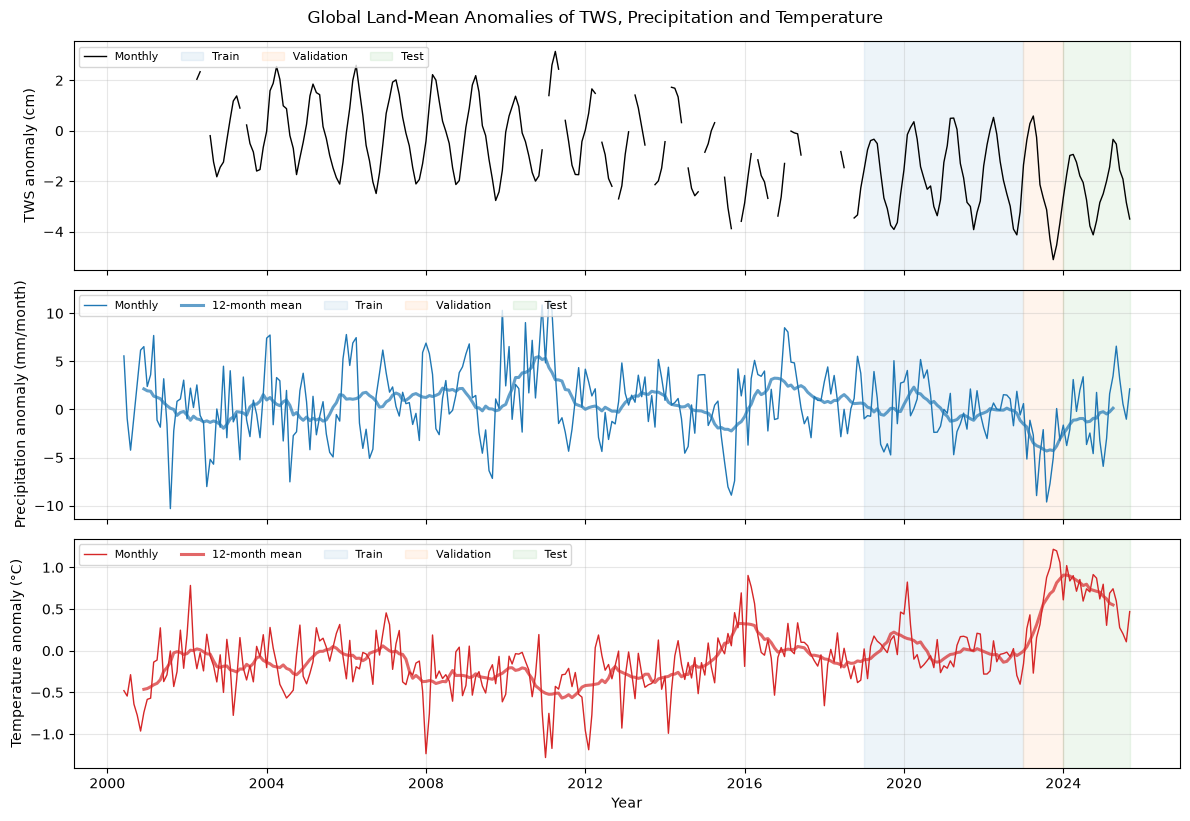

In [32]:
panels = [
    ("TWS anomaly (cm)", land_mean(cube.tws), "black"),
    ("Precipitation anomaly (mm/month)", land_mean(ANOM["precip"]), "tab:blue"),
    ("Temperature anomaly (°C)", land_mean(ANOM["t2m"]), "tab:red"),
]
split_colors = {"train": "tab:blue", "validation": "tab:orange", "test": "tab:green"}

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

for ax, (label, series, color) in zip(axes, panels):
    ax.plot(cube.times, series, color=color, lw=1, label="Monthly")
    if label != "TWS anomaly (cm)":
        smooth = pd.Series(series).rolling(12, center=True).mean()
        ax.plot(cube.times, smooth, color=color, lw=2.2, alpha=0.7, label="12-month mean")

    # Shade the train / validation / test periods
    for split, split_color in split_colors.items():
        start = pd.Timestamp(config["splits"][split]["start"])
        end = min(pd.Timestamp(config["splits"][split]["end"]), cube.times[-1])
        ax.axvspan(start, end, color=split_color, alpha=0.08, label=split.title())

    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8, ncol=5)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.suptitle("Global Land-Mean Anomalies of TWS, Precipitation and Temperature", y=1.02)
plt.savefig(FIGURES_DIR / "p_t_tws_01_global_series.png", dpi=150, bbox_inches="tight")
plt.show()


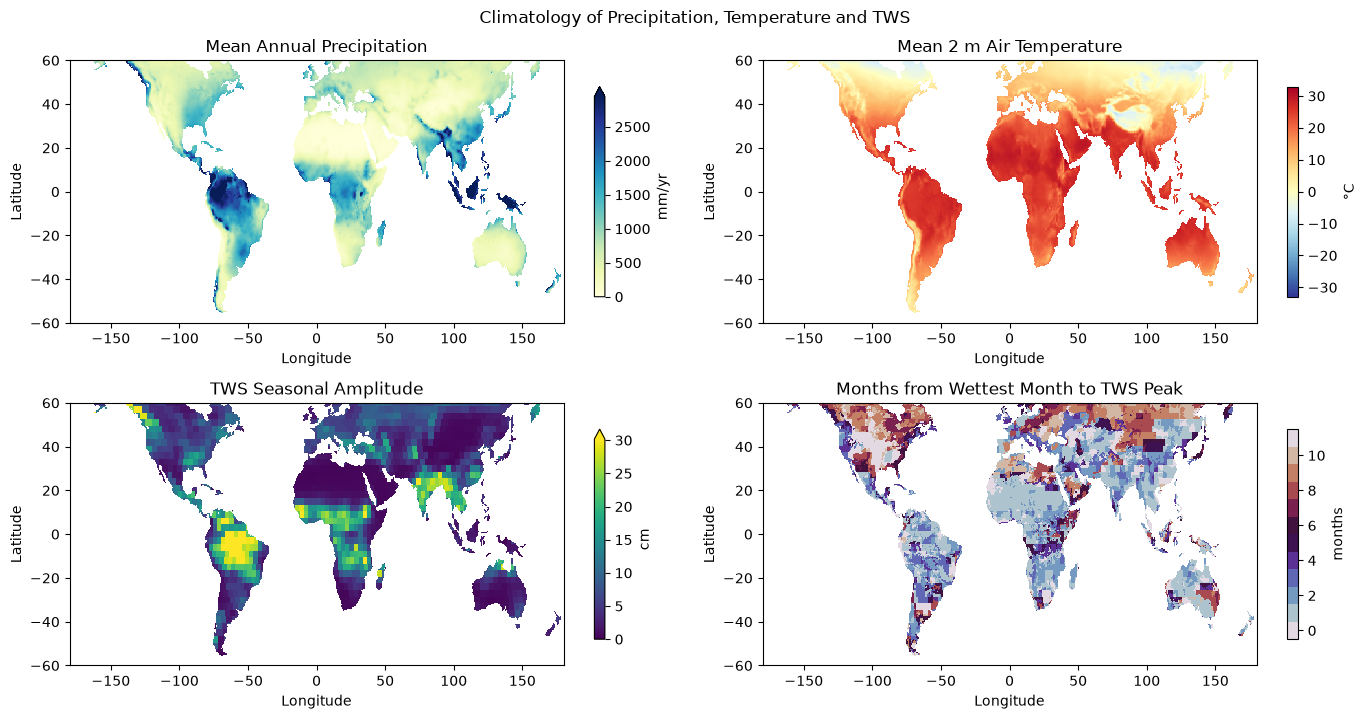

Median seasonal phase lag P→TWS: 2 months (IQR 1–7)


In [33]:
annual_precip = np.nanmean(cube.precip[ANALYSIS], axis=0) * 12
mean_temperature = np.nanmean(cube.t2m[ANALYSIS], axis=0)
tws_amplitude = (np.nanmax(CLIM["tws"], axis=0) - np.nanmin(CLIM["tws"], axis=0)) / 2
phase_lag = analysis.seasonal_phase_lag(CLIM)  # months from wettest month to TWS peak

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

draw_map(axes[0, 0], annual_precip, "Mean Annual Precipitation",
         "YlGnBu", 0, np.nanpercentile(annual_precip, 98), "mm/yr")
draw_map(axes[0, 1], mean_temperature, "Mean 2 m Air Temperature",
         "RdYlBu_r", label="°C")
draw_map(axes[1, 0], tws_amplitude, "TWS Seasonal Amplitude",
         "viridis", 0, np.nanpercentile(tws_amplitude, 98), "cm")
draw_map(axes[1, 1], phase_lag, "Months from Wettest Month to TWS Peak",
         plt.get_cmap("twilight", 12), -0.5, 11.5, "months")

plt.tight_layout()
plt.suptitle("Climatology of Precipitation, Temperature and TWS", y=1.02)
plt.savefig(FIGURES_DIR / "p_t_tws_02_climatology.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Median seasonal phase lag P→TWS: {np.nanmedian(phase_lag):.0f} months "
      f"(IQR {np.nanpercentile(phase_lag, 25):.0f}–{np.nanpercentile(phase_lag, 75):.0f})")


## 5. Trend analysis (P, T, and TWS for comparison)
Mann–Kendall test with the **Hamed–Rao** variance correction for autocorrelation on deseasonalized monthly
series, **Theil–Sen** slope (per year), and **Benjamini–Hochberg** FDR at q = 0.05 across pixels. The same
function can be reused for the TWS trend maps (Phase 1). This step is slow (~20 minutes for ~46k pixels);
raise `n_jobs` in the config to parallelize it.

Trend maps in 1902s
Trend maps in 589s


,variable,pct_sig_increasing,pct_sig_decreasing,period
0,precip,3.6,5.5,full record
1,t2m,38.5,3.2,full record
2,tws,28.1,37.9,full record
0,precip,1.8,2.9,GRACE-FO
1,t2m,26.4,0.1,GRACE-FO
2,tws,23.9,35.4,GRACE-FO


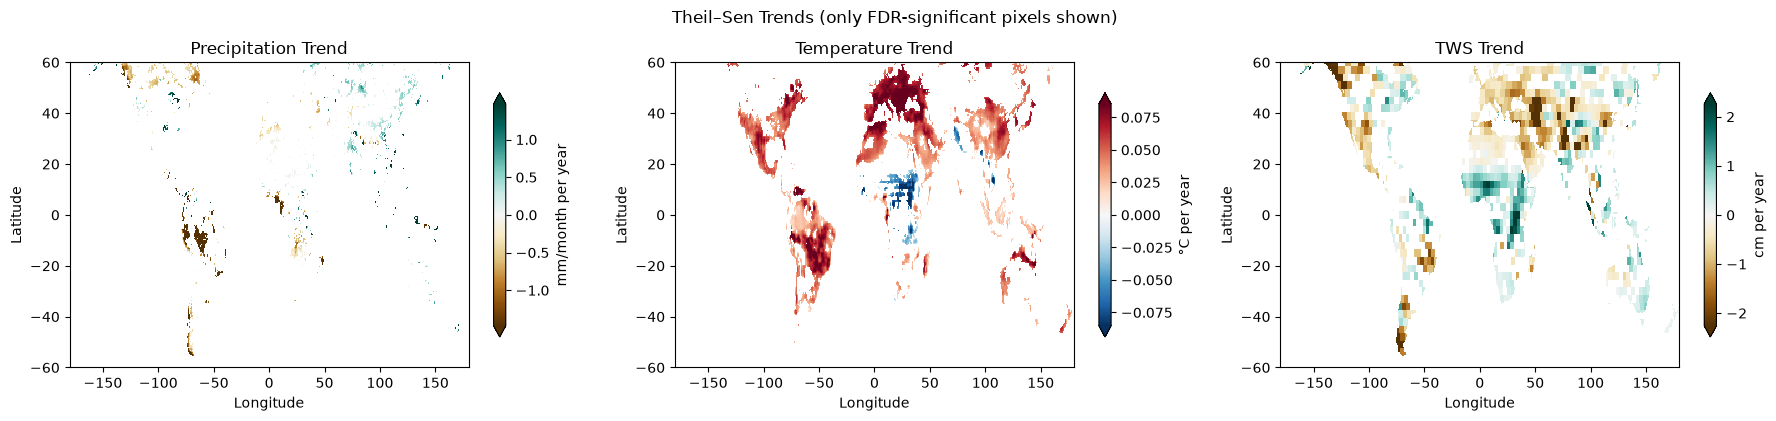

In [34]:
TRENDS = analysis.trend_analysis(cube, ANOM, config, ANALYSIS)
TRENDS_GFO = analysis.trend_analysis(cube, ANOM, config, cube.period(config["analysis"]["gracefo_trend_start"]))
trend_table = pd.concat([
    analysis.trend_shares(TRENDS).assign(period="full record"),
    analysis.trend_shares(TRENDS_GFO).assign(period="GRACE-FO"),
])
trend_table.to_csv(METRICS_DIR / "p_t_tws_trend_summary.csv", index=False)
analysis.trend_dataset(cube, TRENDS).to_netcdf(PROCESSED_DIR / "p_t_tws_trend_maps.nc")
display(trend_table)

trend_panels = [
    ("precip", "Precipitation Trend", "mm/month per year", "BrBG"),
    ("t2m", "Temperature Trend", "°C per year", "RdBu_r"),
    ("tws", "TWS Trend", "cm per year", "BrBG"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, (name, title, unit, cmap) in zip(axes, trend_panels):
    slope, p_value, significant = TRENDS[name]
    limit = np.nanpercentile(np.abs(slope), 97)  # symmetric colour scale
    draw_map(ax, np.where(significant, slope, np.nan), title, cmap, -limit, limit, unit)

plt.tight_layout()
plt.suptitle("Theil–Sen Trends (only FDR-significant pixels shown)", y=1.04)
plt.savefig(FIGURES_DIR / "p_t_tws_03_trends.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Relationships between TWS and precipitation / temperature
TWS is a **storage**, so physically it should track **accumulated** precipitation (water balance:
dS/dt = P − ET − Q), with temperature acting mainly through evapotranspiration and snowmelt. We test:

* `r(TWS, P lagged)` for lags 0–6 months
* `r(TWS, cumulative P over w months)`; the best window w is a pixel-wise memory time scale
* `r(TWS, T lagged)` and the **partial** correlation of TWS with T after removing the best cumulative-P signal
* `r(ΔTWS, P)`: month-to-month storage change vs precipitation (water-balance check)

All series are deseasonalized (training climatology) and linearly detrended over the analysis period, so
shared long-term trends do not create spurious correlations. p-values use an effective sample size
n_eff = n(1 − r₁ˣr₁ʸ)/(1 + r₁ˣr₁ʸ) (Bretherton et al., 1999), then BH-FDR across pixels.

In [13]:
RELATIONSHIPS = analysis.driver_relationships(cube, ANOM, config)
corr_table = analysis.correlation_summary(RELATIONSHIPS, cube.area_weight, config["analysis"]["fdr_q"])
corr_table.to_csv(METRICS_DIR / "p_t_tws_correlation_summary.csv", index=False)
analysis.correlation_dataset(cube, RELATIONSHIPS).to_netcdf(PROCESSED_DIR / "p_t_tws_correlation_maps.nc")
display(corr_table)

print("Best cumulative-P window (months), share of pixels:")
print(pd.Series(RELATIONSHIPS["best_cumulative_window"]).value_counts(normalize=True).sort_index().round(3).to_string())
print("\nMost-negative T lag (months), share of pixels:")
print(pd.Series(RELATIONSHIPS["most_negative_temperature_lag"]).value_counts(normalize=True).sort_index().round(3).to_string())

,relationship,median_r,area_wtd_mean_r,pct_sig_pos,pct_sig_neg
0,"r(TWS, P) lag 0",0.136,0.141,42.109,0.099
1,"r(TWS, P) best lag",0.255,0.253,85.060,0.006
2,"r(TWS, cumP) best window",0.519,0.474,70.938,0.065
3,"r(TWS, T) lag 0",-0.160,-0.175,0.846,45.207
4,"r(TWS, T) most negative lag",-0.208,-0.220,0.067,59.199
5,"partial r(TWS, T | cumP)",-0.108,-0.113,1.144,27.294
6,"r(ΔTWS, P)",0.258,0.242,76.809,0.253


Best cumulative-P window (months), share of pixels:
1     0.020
3     0.081
6     0.102
9     0.157
12    0.187
18    0.134
24    0.319

Most-negative T lag (months), share of pixels:
0    0.316
1    0.240
2    0.083
3    0.104
4    0.068
5    0.099
6    0.090


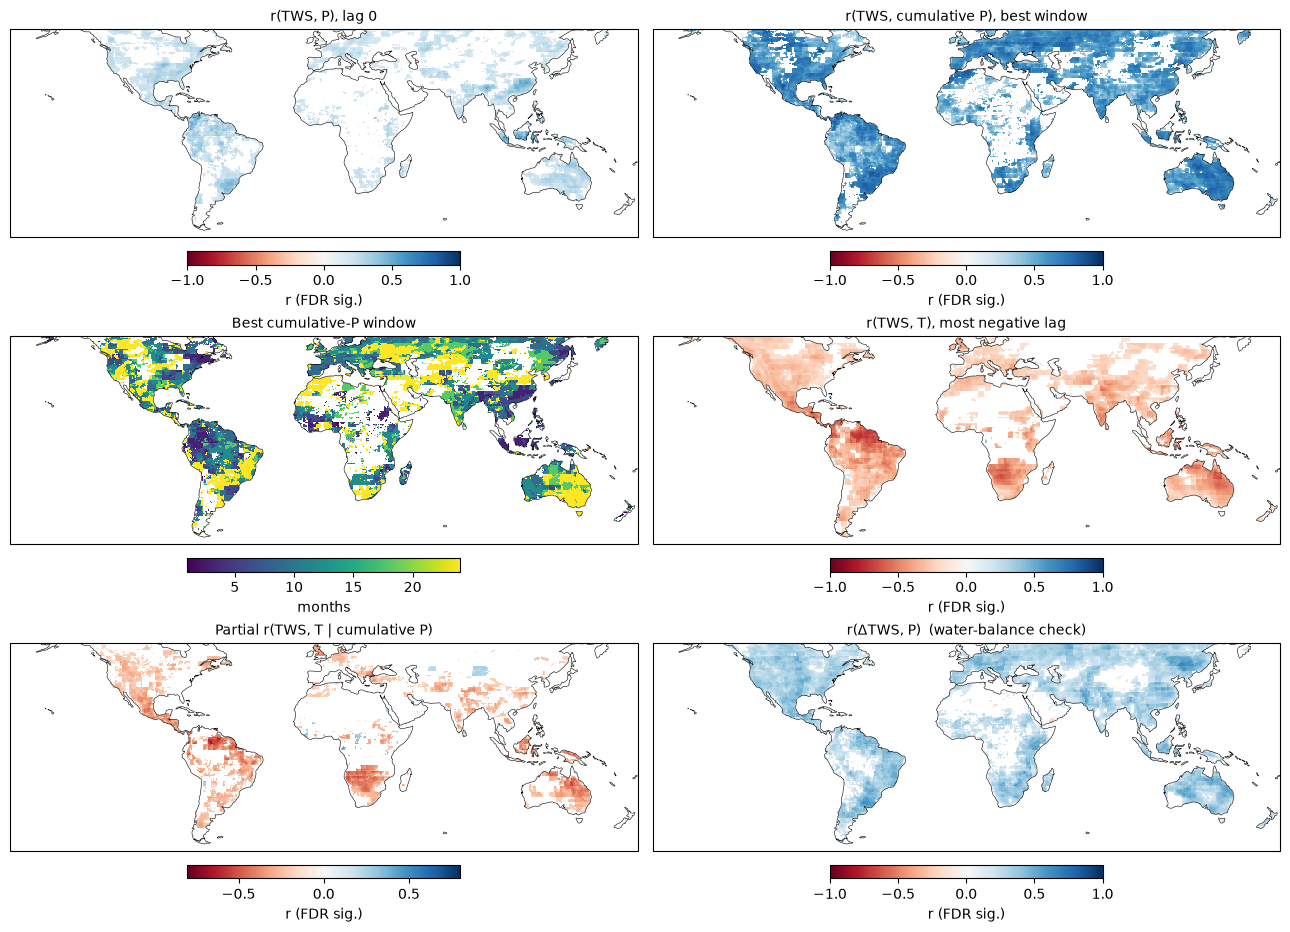

In [ ]:
best_cumP_r, best_cumP_p, _ = RELATIONSHIPS["best_cumulative_precip"]
best_window = np.where(
    analysis.bh_fdr(best_cumP_p, config["analysis"]["fdr_q"]),
    RELATIONSHIPS["best_cumulative_window"], np.nan,
)

panels = [
    (significant_only(*RELATIONSHIPS["correlations"]["P_lag0"]),
     "TWS vs Same-Month Precipitation", "RdBu", -1, 1, "r"),
    (significant_only(best_cumP_r, best_cumP_p),
     "TWS vs Accumulated Precipitation (best window)", "RdBu", -1, 1, "r"),
    (best_window, "Best Accumulation Window", "viridis", None, None, "months"),
    (significant_only(*RELATIONSHIPS["most_negative_temperature"][:2]),
     "TWS vs Temperature (most negative lag)", "RdBu", -1, 1, "r"),
    (significant_only(*RELATIONSHIPS["partial_temperature"]),
     "TWS vs Temperature after Removing Rainfall", "RdBu", -0.8, 0.8, "partial r"),
    (significant_only(*RELATIONSHIPS["water_balance"]),
     "Monthly TWS Change vs Precipitation", "RdBu", -1, 1, "r"),
]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for ax, (values, title, cmap, vmin, vmax, label) in zip(axes.ravel(), panels):
    draw_map(ax, values, title, cmap, vmin, vmax, label)

plt.tight_layout()
plt.suptitle("How TWS Relates to Precipitation and Temperature (FDR-significant pixels only)", y=1.02)
plt.savefig(FIGURES_DIR / "p_t_tws_04_tws_driver_correlations.png", dpi=150, bbox_inches="tight")
plt.show()


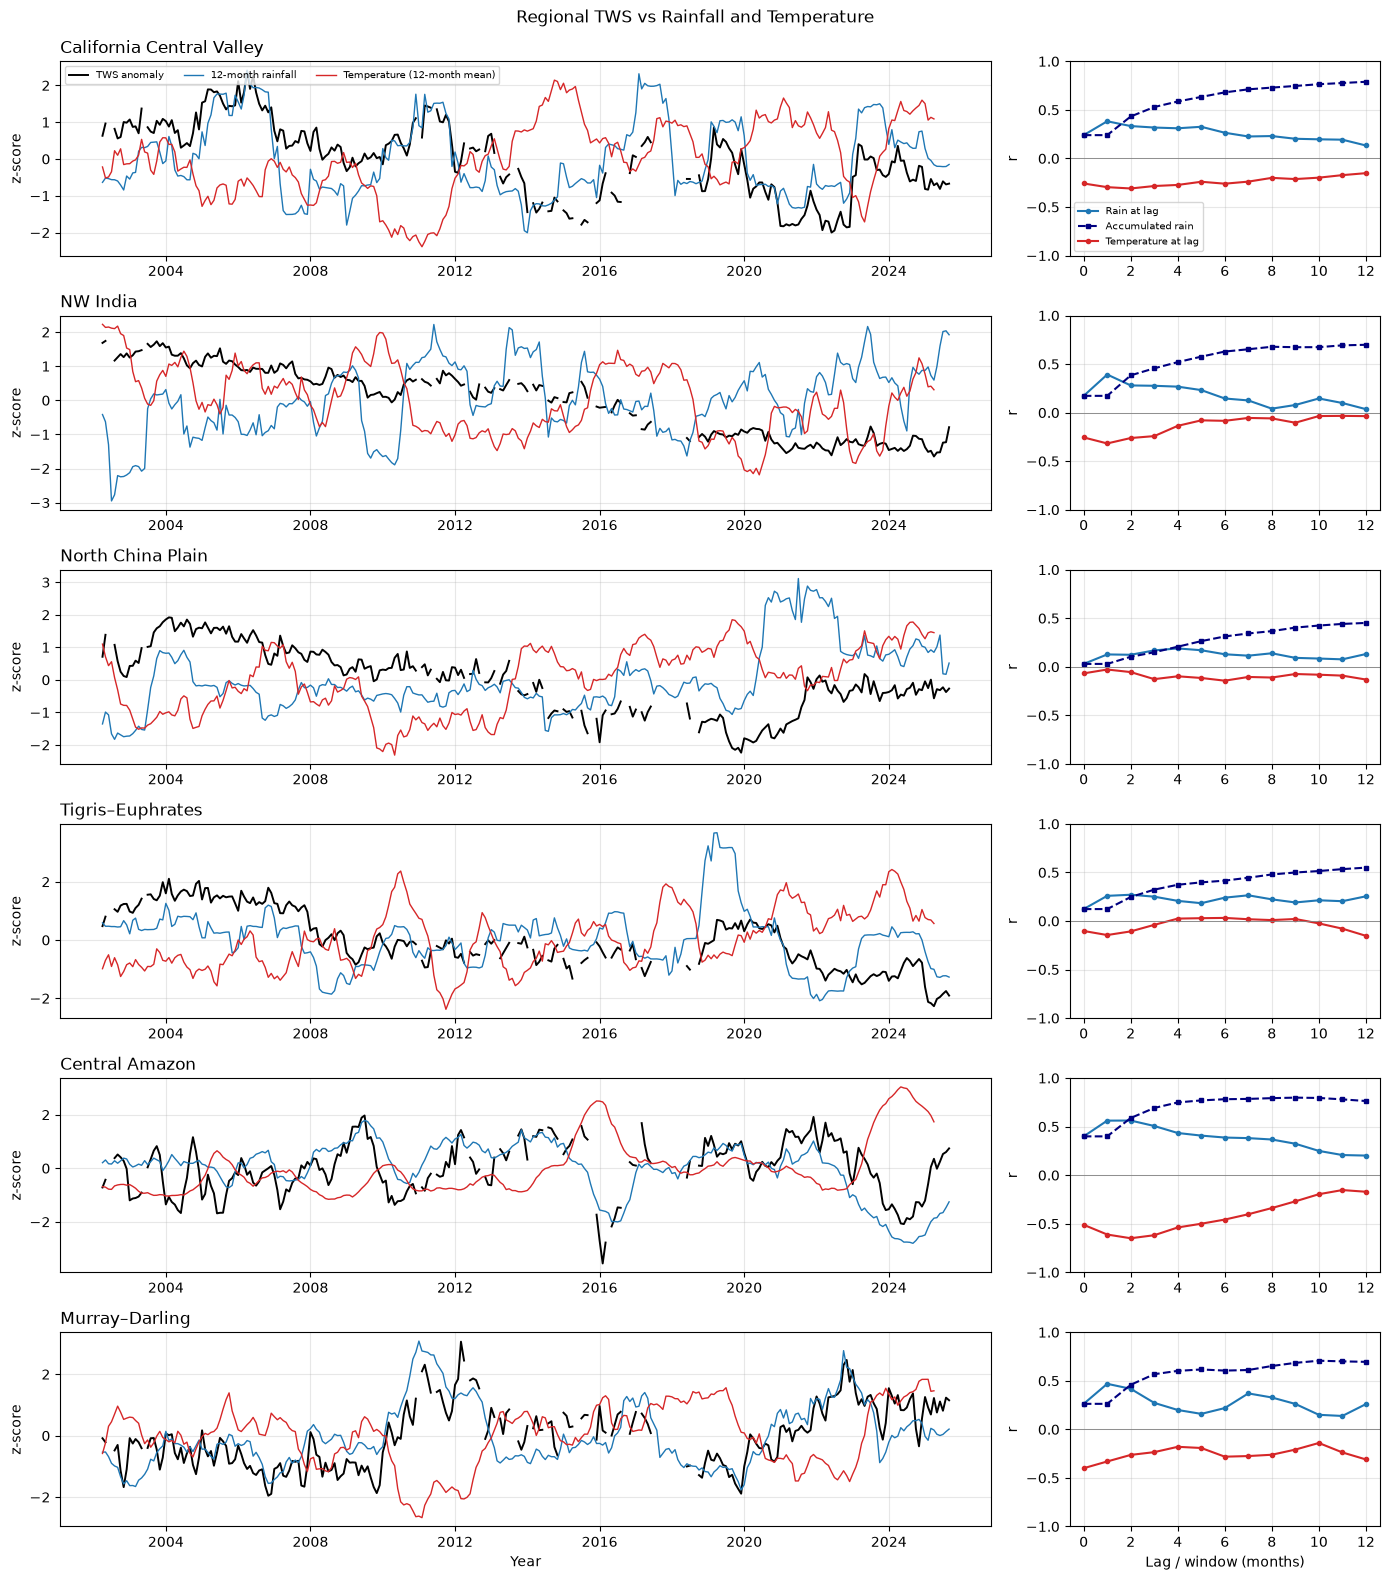

In [35]:
years = cube.years
lags = np.arange(13)
regions = {name: bounds for name, bounds in config["regions"].items() if len(cube.region_index(bounds))}


def zscore(x):
    return (x - np.nanmean(x)) / np.nanstd(x)


def detrended_corr(a, b):
    """Correlation of two regional series after removing their linear trends."""
    a = analysis.detrend(a[:, None], ANALYSIS, years)
    b = analysis.detrend(b[:, None], ANALYSIS, years)
    return analysis.nan_corr(a, b)[0][0]


fig, axes = plt.subplots(len(regions), 2, figsize=(14, 2.6 * len(regions)),
                         gridspec_kw={"width_ratios": [3, 1]})

for (ax_series, ax_lags), (name, bounds) in zip(axes, regions.items()):
    tws = cube.region_mean(np.where(ANALYSIS[:, None], ANOM["tws"], np.nan), bounds)
    precip = cube.region_mean(ANOM["precip"], bounds)
    temp = cube.region_mean(ANOM["t2m"], bounds)
    precip_12 = cube.region_mean(analysis.rolling_sum(ANOM["precip"], 12), bounds)
    temp_12 = pd.Series(temp).rolling(12, center=True).mean().values

    # Left: TWS, 12-month rainfall and temperature on one z-score scale
    times = cube.times[ANALYSIS]
    ax_series.plot(times, zscore(tws[ANALYSIS]), color="black", lw=1.4, label="TWS anomaly")
    ax_series.plot(times, zscore(precip_12[ANALYSIS]), color="tab:blue", lw=1, label="12-month rainfall")
    ax_series.plot(times, zscore(temp_12[ANALYSIS]), color="tab:red", lw=1, label="Temperature (12-month mean)")
    ax_series.set_title(name, loc="left")
    ax_series.set_ylabel("z-score")
    ax_series.grid(alpha=0.3)

    # Right: how strongly TWS correlates with rain and temperature at each lag / window
    precip_lag_r = [detrended_corr(tws, analysis.shift(precip[:, None], lag)[:, 0]) for lag in lags]
    cum_precip_r = [detrended_corr(tws, analysis.rolling_sum(precip[:, None], max(lag, 1))[:, 0]) for lag in lags]
    temp_lag_r = [detrended_corr(tws, analysis.shift(temp[:, None], lag)[:, 0]) for lag in lags]

    ax_lags.plot(lags, precip_lag_r, "o-", ms=3, color="tab:blue", label="Rain at lag")
    ax_lags.plot(lags, cum_precip_r, "s--", ms=3, color="navy", label="Accumulated rain")
    ax_lags.plot(lags, temp_lag_r, "o-", ms=3, color="tab:red", label="Temperature at lag")
    ax_lags.axhline(0, color="grey", lw=0.6)
    ax_lags.set_ylim(-1, 1)
    ax_lags.set_ylabel("r")
    ax_lags.grid(alpha=0.3)

axes[0, 0].legend(fontsize=7, ncol=3, loc="upper left")
axes[0, 1].legend(fontsize=7)
axes[-1, 0].set_xlabel("Year")
axes[-1, 1].set_xlabel("Lag / window (months)")

plt.tight_layout()
plt.suptitle("Regional TWS vs Rainfall and Temperature", y=1.01)
plt.savefig(FIGURES_DIR / "p_t_tws_05_regional_drivers.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Features for the baselines
Driver features are built on the full P/T record (from 2000-06), so lags and cumulative sums exist from the
first GRACE month. All anomalies use the training climatology. With `setup: nowcast` the month-t drivers are
used; `setup: forecast` shifts every driver by one month.

In [16]:
RNG = np.random.default_rng(config["baselines"]["seed"])
FEATURES, FEATURE_SETS, DRIVERS = baselines.build_features(cube, ANOM, config["baselines"])
print(f"Setup: {config['baselines']['setup']}. Drivers: {DRIVERS}")
display(pd.Series({name: ", ".join(columns) for name, columns in FEATURE_SETS.items()}, name="features").to_frame())

Setup: nowcast. Drivers: ['p_lag0', 'p_lag1', 'cumP3', 'cumP12', 't_lag0', 't_lag1']


,features
Seasonal + trend,"h0, h1, h2, h3, trend"
"LR (P,T)","h0, h1, h2, h3, p_lag0, p_lag1, cumP3, cumP12,..."
"LR (P,T) + trend","h0, h1, h2, h3, trend, p_lag0, p_lag1, cumP3, ..."
"ARX (P,T,trend,TWS t-1)","h0, h1, h2, h3, trend, p_lag0, p_lag1, cumP3, ..."


## 8. Baselines on the GRACE-FO temporal split
* Ridge regularisation strength (except for the plain OLS *Seasonal + trend* fit) is chosen on the validation
  period (area-weighted RMSE), then every model is **refit on train + validation** and evaluated once on the
  GRACE-FO test period.
* **Pooled gradient boosting on seasonal-trend residuals:** one model for all pixels learns how the residual of
  the per-pixel *Seasonal + trend* fit responds to precipitation and temperature anomalies, modulated by static
  climate descriptors (latitude, mean P, mean T, P seasonality). Boosting iterations are selected on the
  validation period, then the model is refit on train + validation.
* All models are scored on the **same** test cells: months where TWS(t) and TWS(t−1) are both observed and
  every model has a prediction. That keeps one-step models (persistence, ARX) comparable with
  climate-driven ones.
* Metrics: RMSE, NSE, Pearson r, **anomaly r** (after removing the train + validation monthly climatology, i.e. skill on
  non-seasonal variability), and **MSESS vs climatology** (pooled, area-weighted).

In [17]:
TEMPORAL = baselines.temporal_split_baselines(cube, FEATURES, FEATURE_SETS, DRIVERS, CLIM, config, RNG)
test_table = TEMPORAL["metrics"]
test_table.to_csv(METRICS_DIR / "p_t_tws_baseline_metrics_gracefo.csv")
test_table

Seasonal + trend             alpha=1e-06  val RMSE=8.34 cm
LR (P,T)                     alpha=10.0   val RMSE=8.06 cm
LR (P,T) + trend             alpha=10.0   val RMSE=6.30 cm
ARX (P,T,trend,TWS t-1)      alpha=10.0   val RMSE=4.49 cm
GBM iterations chosen on validation: 362
Test cells: 972825 (months × pixels), 21 months


,MAE_cm,RMSE_cm,r_area_wtd,anom_r_area_wtd,NSE_median,pct_NSE_pos,n_cells,MSESS_vs_clim
Seasonal persistence,2.347,2.958,0.797,0.618,0.655,88.715,46325.0,0.860
"ARX (P,T,trend,TWS t-1)",2.896,3.482,0.816,0.667,0.592,81.764,46325.0,0.789
Persistence,3.482,4.249,0.742,0.575,0.546,95.883,46325.0,0.636
"LR (P,T) + trend",4.391,5.122,0.700,0.443,0.181,57.079,46325.0,0.514
"Seasonal-trend + GBM (P,T)",5.320,6.017,0.698,0.426,-0.093,47.309,46325.0,0.309
"LR (P,T)",5.500,6.255,0.666,0.385,-0.093,47.374,46325.0,0.141
Seasonal + trend,5.814,6.564,0.640,0.229,-0.189,43.499,46325.0,0.136
Climatology,6.096,6.877,0.596,NaN,-0.244,40.376,46325.0,0.000


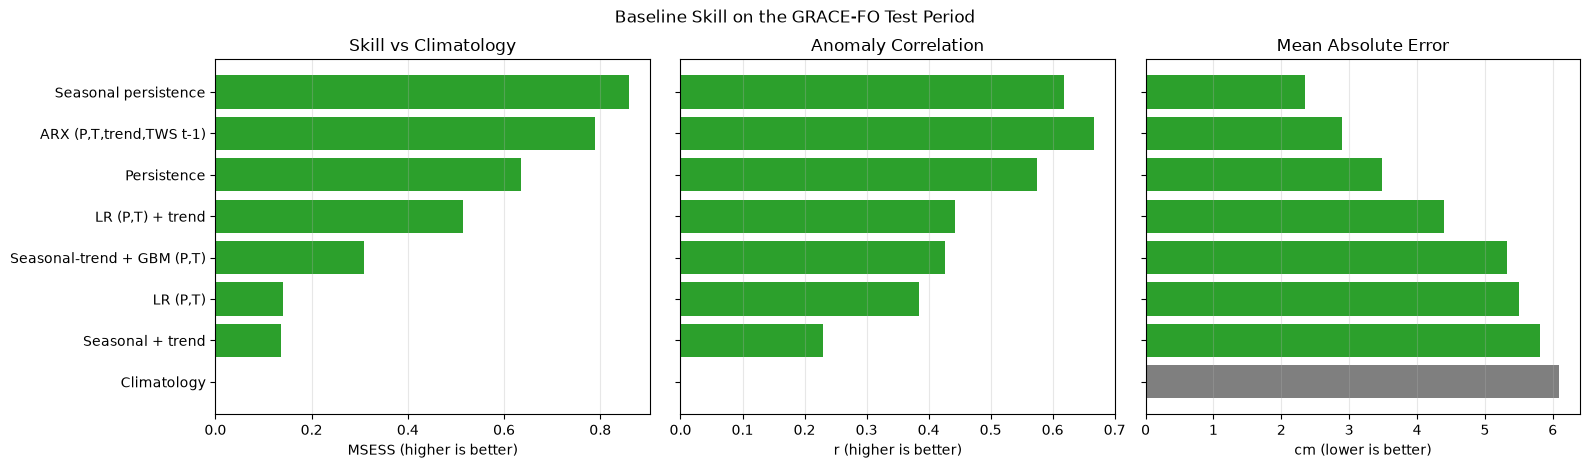

In [36]:
ranked = test_table.sort_values("MSESS_vs_clim")  # best model at the top

panels = [
    ("MSESS_vs_clim", "Skill vs Climatology", "MSESS (higher is better)"),
    ("anom_r_area_wtd", "Anomaly Correlation", "r (higher is better)"),
    ("MAE_cm", "Mean Absolute Error", "cm (lower is better)"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, (column, title, xlabel) in zip(axes, panels):
    # Green = beats climatology, grey = does not
    colors = ["tab:green" if skill > 0 else "tab:grey" for skill in ranked["MSESS_vs_clim"]]
    ax.barh(ranked.index, ranked[column], color=colors)
    ax.axvline(0, color="black", lw=0.6)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.suptitle("Baseline Skill on the GRACE-FO Test Period", y=1.03)
plt.savefig(FIGURES_DIR / "p_t_tws_06_baseline_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


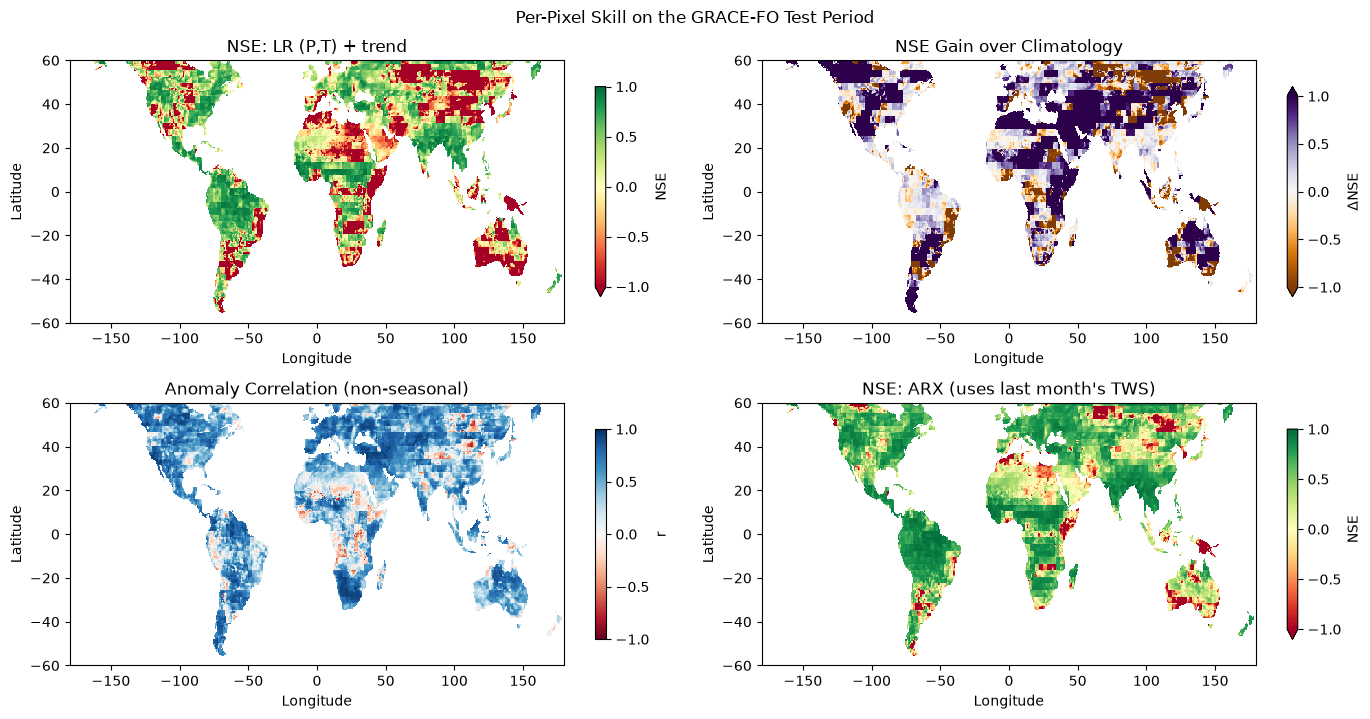

In [37]:
skill = TEMPORAL["maps"]
best_climate = baselines.best_climate_model(test_table)  # best model without past TWS
best_nse = skill[best_climate]["nse"]

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

draw_map(axes[0, 0], best_nse, f"NSE: {best_climate}", "RdYlGn", -1, 1, "NSE")
draw_map(axes[0, 1], best_nse - skill["Climatology"]["nse"],
         "NSE Gain over Climatology", "PuOr", -1, 1, "ΔNSE")
draw_map(axes[1, 0], skill[best_climate]["r_anom"],
         "Anomaly Correlation (non-seasonal)", "RdBu", -1, 1, "r")
draw_map(axes[1, 1], skill["ARX (P,T,trend,TWS t-1)"]["nse"],
         "NSE: ARX (uses last month's TWS)", "RdYlGn", -1, 1, "NSE")

plt.tight_layout()
plt.suptitle("Per-Pixel Skill on the GRACE-FO Test Period", y=1.02)
plt.savefig(FIGURES_DIR / "p_t_tws_07_skill_maps.png", dpi=150, bbox_inches="tight")
plt.show()


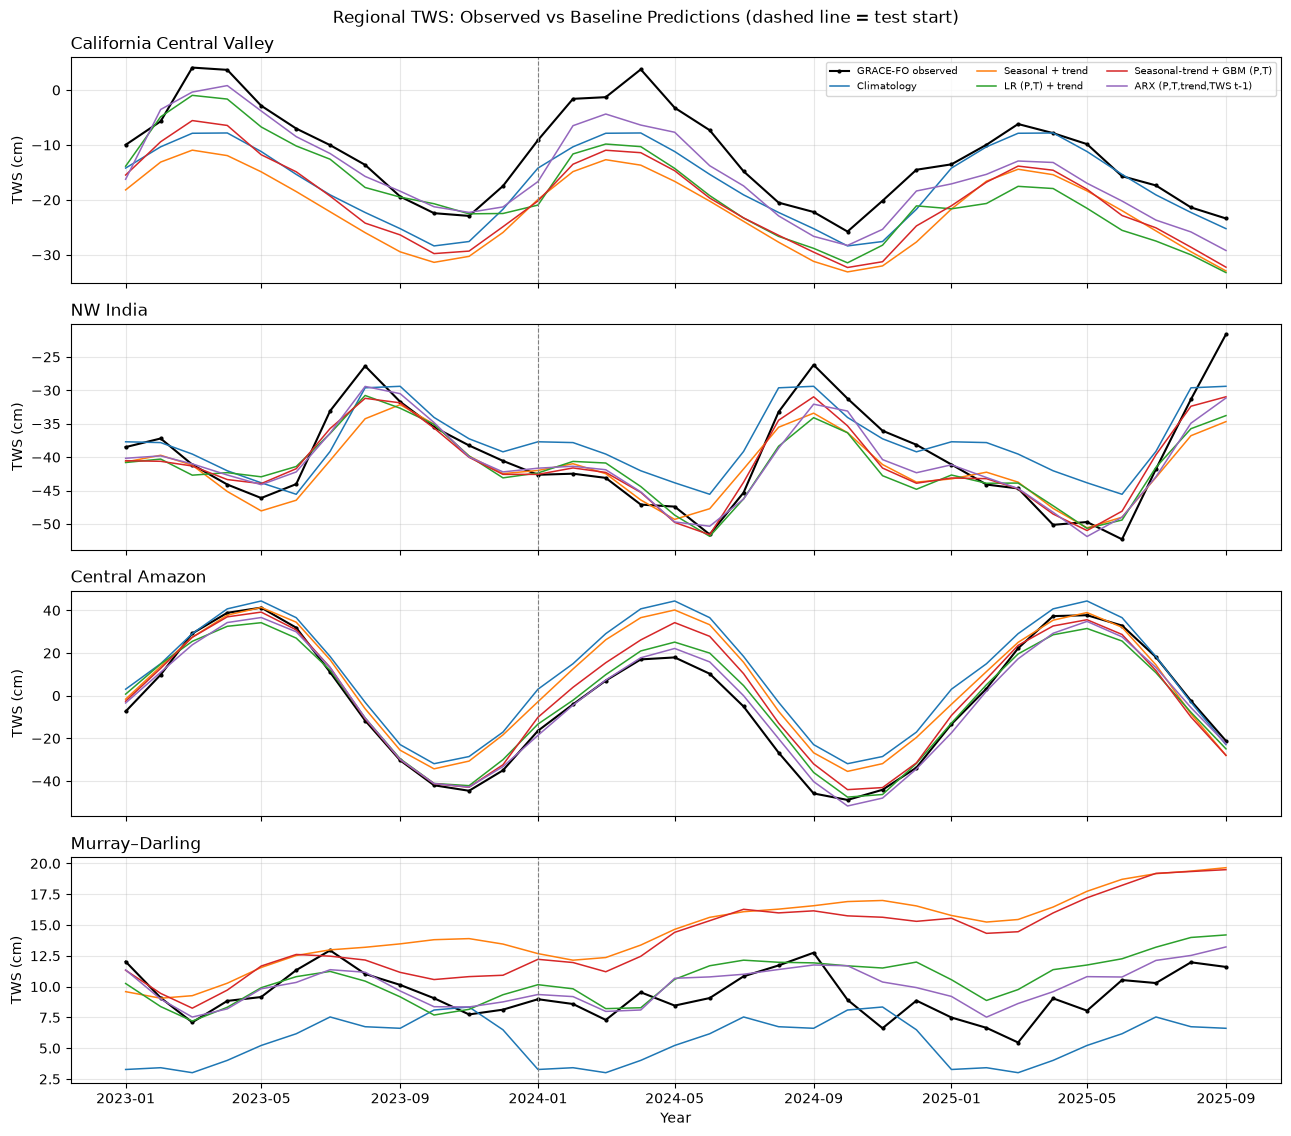

In [38]:
models_to_show = [
    "Climatology", "Seasonal + trend", "LR (P,T) + trend",
    "Seasonal-trend + GBM (P,T)", "ARX (P,T,trend,TWS t-1)",
]
region_names = ["California Central Valley", "NW India", "Central Amazon", "Murray–Darling"]

baseline_predictions = TEMPORAL["predictions"]
window = cube.times >= pd.Timestamp(config["splits"]["validation"]["start"])  # validation + test
test_start = pd.Timestamp(config["splits"]["test"]["start"])

fig, axes = plt.subplots(len(region_names), 1, figsize=(13, 2.8 * len(region_names)), sharex=True)

for ax, name in zip(axes, region_names):
    bounds = config["regions"][name]
    observed = cube.region_mean(cube.tws, bounds)
    ax.plot(cube.times[window], observed[window], "k.-", lw=1.5, ms=4, label="GRACE-FO observed")

    for model in models_to_show:
        predicted = cube.region_mean(baseline_predictions[model], bounds)
        ax.plot(cube.times[window], predicted[window], lw=1.1, label=model)

    ax.axvline(test_start, color="grey", ls="--", lw=0.8)  # start of the test period
    ax.set_title(name, loc="left")
    ax.set_ylabel("TWS (cm)")
    ax.grid(alpha=0.3)

axes[0].legend(fontsize=7, ncol=3)
axes[-1].set_xlabel("Year")

plt.tight_layout()
plt.suptitle("Regional TWS: Observed vs Baseline Predictions (dashed line = test start)", y=1.01)
plt.savefig(FIGURES_DIR / "p_t_tws_08_regional_predictions.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Geographic generalization: spatial block cross-validation
Per-pixel models cannot be applied to a pixel they were never trained on, so this setting uses **pooled**
models only. Pixels are grouped into 10°×10° blocks and blocks are assigned to 5 folds; each fold's pixels are
predicted by a model trained on the other folds, **using no TWS information from the held-out pixels**.
Inputs: P/T anomaly features, harmonics, the pixel's own P/T climatology for the current month, and static
descriptors. Target: raw TWS anomaly over all observed months. Reference: a zero predictor (GRACE anomalies are
relative to a time mean).

fold 0: train pixels 35417, test pixels 10908
fold 1: train pixels 36475, test pixels 9850
fold 2: train pixels 39240, test pixels 7085
fold 3: train pixels 35856, test pixels 10469
fold 4: train pixels 38312, test pixels 8013


,MAE_cm,RMSE_cm,r_area_wtd,anom_r_area_wtd,NSE_median,pct_NSE_pos,n_cells,MSESS_vs_zero
Zero (time-mean),8.902,11.065,NaN,0.073,-0.238,0.000,46325.0,0.00
"Pooled ridge (P,T)",8.725,10.779,0.343,0.214,-0.261,33.675,46325.0,0.06
"Pooled GBM (P,T)",7.693,9.474,0.522,0.318,0.014,50.873,46325.0,0.24


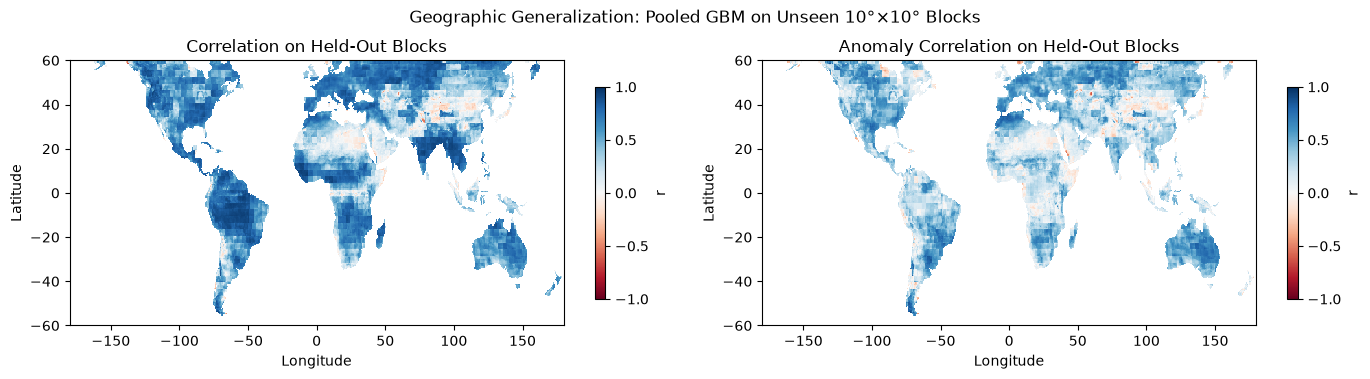

In [39]:
SPATIAL = baselines.spatial_cv_baselines(
    cube, FEATURES, DRIVERS, CLIM, TEMPORAL["static"], TEMPORAL["tws_climatology"], config, RNG
)
sp_table = SPATIAL["metrics"]
sp_table.to_csv(METRICS_DIR / "p_t_tws_baseline_metrics_spatial_cv.csv")
display(sp_table)

gbm_skill = SPATIAL["maps"]["Pooled GBM (P,T)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))

draw_map(axes[0], gbm_skill["r"], "Correlation on Held-Out Blocks", "RdBu", -1, 1, "r")
draw_map(axes[1], gbm_skill["r_anom"], "Anomaly Correlation on Held-Out Blocks", "RdBu", -1, 1, "r")

plt.tight_layout()
plt.suptitle("Geographic Generalization: Pooled GBM on Unseen 10°×10° Blocks", y=1.04)
plt.savefig(FIGURES_DIR / "p_t_tws_09_spatial_cv.png", dpi=150, bbox_inches="tight")
plt.show()


## 10. Save predictions and splits for the deep-learning comparison


In [22]:
predictions_path = PROCESSED_DIR / "p_t_tws_baseline_predictions.nc"
predictions = baselines.prediction_dataset(cube, TEMPORAL, SPATIAL, config)
predictions.to_netcdf(predictions_path, engine="netcdf4", encoding=compressed_float_encoding(predictions))

model_path = MODELS_DIR / "p_t_tws_baselines.json"
specification = baselines.model_specification(cube, TEMPORAL, FEATURE_SETS, config, ALIGNED_FILE.relative_to(PROJECT_ROOT))
model_path.write_text(json.dumps(specification, indent=2, default=str) + "\n")
print("Saved:", predictions_path.relative_to(PROJECT_ROOT), "and", model_path.relative_to(PROJECT_ROOT))

Saved: data/processed/p_t_tws_baseline_predictions.nc and models/p_t_tws_baselines.json


## 11. Observations and EDA findings

### Data
* P and T: Jun 2000 – Sep 2025 (304 months).
* GRACE: from Apr 2002; 248 of 282 months observed.
* Most gaps come from the GRACE → GRACE-FO break.
* Splits: train 48, validation 12, test 21 months.


### TWS vs rain and temperature
* Same-month rain: weak link (r = 0.14).
* Accumulated rain: strong link (r = 0.52, 71% of pixels).
* Storage memory is long: ≥ 12 months in ~65% of pixels.
* Strongest regions: California 0.79, Amazon 0.76.
* Weakest regions: North China Plain 0.45.
* Warmer months implies less storage (r ≈ −0.2).
* Temperature still matters after removing rain effects in ~27% of pixels.
* Water balance holds: storage change tracks rain in 77% of pixels.
* TWS peaks ~2 months after the wettest month.
* Some regions lag 8–10 months (likely snow or groundwater).

### Feature takeaways
* Use 12–24+ months of rainfall history.
* Include temperature and its lags.
* Add season and climate descriptors.
* Add a trend term: skill rises from 0.14 → 0.51.
* Rain and temperature can't explain long-term losses.
* Human water-use data is a good next input.
* Last month's TWS is the strongest predictor.

### Baseline results (test period)
* With last month's TWS: seasonal persistence is best (0.86).
* Rain and temperature only: per-pixel linear + trend is best (0.51).
* Pooled gradient boosting is weaker (0.31).
* Unseen regions are hardest: best is 0.26.

### Targets for deep-learning models
* Rain and temperature only: beat 0.51 (anomaly r 0.44).
* With past TWS: beat 0.86.
* Unseen regions: beat 0.26.

